# AH2179 Traffic project — A3: Model graphs and statistical analysis

Uses the models saved by **A2** (`models_allday/`) and the features from **A1** — run A1 and A2 first. Nothing is retrained here.

**What is tested** (target: flow at portal 55.620, 15 min ahead, all day):

| # | Question | Test(s) |
|---|---|---|
| H1 | Is the selected model (XGBoost + augmentation) more accurate than persistence / historical average? | paired day-level t-test + Wilcoxon, Diebold–Mariano |
| H2 | Does the regime-split model differ from the single model? | same |
| H3 | Does masking augmentation cost accuracy when no sensor fails? | same |
| H4 | Does XGBoost differ from ridge and the MLP? | same |
| H5 | Are all models equally good? | Friedman test + Nemenyi post-hoc |
| H6 | Are the forecasts unbiased and efficient? | Mincer–Zarnowitz regression (HAC), bias t-test |
| H7 | Are the errors white noise / normal? | Ljung–Box (lags ≥ horizon), Jarque–Bera |
| H8 | Is the error larger in congestion? | Mann–Whitney, Brown–Forsythe, day-level Wilcoxon |
| H9 | Is 2022 distributed like 2021, and is the bias stable over months? | Kolmogorov–Smirnov on daily means, Kruskal–Wallis |
| H10 | Does augmentation improve robustness to sensor failures? | paired day-level tests per failure scenario |

**Why "day-level" tests.** 5-min forecast errors are strongly autocorrelated within a day, so treating ~22 000 rows as independent
would make every p-value tiny. The primary tests therefore use **one value per day** (daily mean squared error), which are close to
independent. The Diebold–Mariano test is the classic alternative: it uses all rows but a HAC (Newey–West) variance that accounts for the
autocorrelation. With several hypotheses, p-values are **Holm-adjusted**. Significance level α = 0.05.

The planned comparisons (H1–H4) are run on the ALL-day **evaluation** file (exploratory) and — with `CONFIRM_ON_FINAL = True`, once
the model choice is frozen — repeated on the **final_evaluation** file (confirmatory). All other analyses use the evaluation file.

In [3]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from scipy import stats
import statsmodels.api as sm
import xgboost as xgb
import traffic_prep as tp

TARGET_P = "p55620"; TARGET = f"q_{TARGET_P}"; Y = f"y_{TARGET}"
SPLIT = "evaluation"            # file used for the diagnostics
CONFIRM_ON_FINAL = True         # also run the planned tests (H1–H4) on final_evaluation
SELECTED = "xgb single + aug"   # the chosen model
ALPHA, SEED, N_BOOT = 0.05, 42, 2000
RES_MIN, H = 5, 3               # 5-min steps; horizon = 3 steps (15 min)

IN = Path("../processed_allday"); MOD = Path("../models_allday"); RES = Path("../results_allday"); FIG = Path("../figures_allday")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9})
def save(fig, name): fig.savefig(FIG / f"A3_{name}.png", bbox_inches="tight", dpi=150)
def show(df, p_cols=(), dec=2):
    '''Display helper: p-values in scientific notation, other numbers rounded.'''
    out = df.copy()
    for c in p_cols: out[c] = out[c].map(lambda v: f"{v:.2g}")
    return out.round(dec)

# ---- saved models from A2 ---------------------------------------------------
prep = joblib.load(MOD / f"prep_{TARGET}.joblib")
X_COLS, DENSE = prep["x_cols"], prep["dense_cols"]
Z = lambda d: prep["scaler"].transform(prep["imputer"].transform(d[X_COLS])[DENSE])
def load_xgb(name):
    m = xgb.XGBRegressor(); m.load_model(MOD / f"{name}_{TARGET}.json"); return m
XM = {k: load_xgb(k) for k in ["xgb_single", "xgb_single_aug", "xgb_split_free", "xgb_split_cong"]}
import tensorflow as tf
try: tf.config.set_visible_devices([], "GPU")   # Mac GPU (tensorflow-metal) gives wrong predictions -> TensorFlow on CPU
except RuntimeError: pass                       # TensorFlow already started in this kernel: restart the kernel
from tensorflow import keras
mlp = keras.models.load_model(MOD / f"mlp_{TARGET}.keras")

R_COL = f"r_{TARGET_P}_lag0"
r_cols = [f"r_{tp.PORTAL_COL[k]}_lag0" for k in tp.PORTALS_DOWNSTREAM]
def route_p(d):   # P(congested at t): target portal, else mean of the other portals, else 0 (same rule as A2)
    return d[R_COL].fillna(d[[c for c in r_cols if c != R_COL]].mean(axis=1)).fillna(0.0)

def predict_all(d):
    hist = d[f"hist_{TARGET}"]; w = route_p(d).to_numpy(); Zd = Z(d)
    return pd.DataFrame({
        "persistence": d[f"{TARGET}_lag0"].fillna(hist),
        "historical average": hist,
        "ridge": prep["ridge"].predict(Zd),
        "mlp": mlp.predict(Zd, verbose=0, batch_size=4096).ravel() * 1000.0,
        "xgb single": XM["xgb_single"].predict(d[X_COLS]),
        "xgb split (soft)": w * XM["xgb_split_cong"].predict(d[X_COLS]) + (1 - w) * XM["xgb_split_free"].predict(d[X_COLS]),
        "xgb single + aug": XM["xgb_single_aug"].predict(d[X_COLS])}, index=d.index)

MODELS = ["persistence", "historical average", "ridge", "mlp", "xgb single", "xgb split (soft)", "xgb single + aug"]
COL = dict(zip(MODELS, ["C7", "C1", "C2", "C4", "C0", "C6", "C3"]))

def make_ctx(split):
    '''Everything needed for one file: valid rows, predictions, errors (pred − obs), metadata, subsets.'''
    D = pd.read_pickle(IN / f"features_{split}.pkl"); D = D[D[Y].notna()]
    P = predict_all(D)[MODELS]; y = D[Y]; E = P.sub(y, axis=0)
    meta = pd.DataFrame({"day": (D.index - pd.Timedelta(minutes=RES_MIN)).normalize(), "tod": D["tod_target_min"],
                         "reg_t": (route_p(D) >= .5).astype(int), "reg_y": D[f"y_reg_{TARGET}"],
                         "offday": D["is_offday"]}, index=D.index)
    sub = {"all day": pd.Series(True, index=D.index),
           "07:30–08:30": meta.tod.between(450, 510),
           "15:00–18:00": meta.tod.between(900, 1080),
           "free flow at t+15": meta.reg_y == 0,
           "congested at t+15": meta.reg_y == 1}
    P.assign(observed=y).to_pickle(RES / f"predictions_{split}_{TARGET}.pkl")
    return dict(split=split, D=D, P=P, y=y, E=E, meta=meta, SUB=sub)

C = make_ctx(SPLIT)
D, P, y, E, meta, SUB = C["D"], C["P"], C["y"], C["E"], C["meta"], C["SUB"]
rmse_tab = pd.DataFrame({s: np.sqrt((E[m] ** 2).mean()) for s, m in SUB.items()}).T
rmse_tab.insert(0, "n", [int(m.sum()) for m in SUB.values()])
print("RMSE (veh/h) — should match the A2 evaluation table:"); rmse_tab.round(0)

RMSE (veh/h) — should match the A2 evaluation table:


,n,persistence,historical average,ridge,mlp,xgb single,xgb split (soft),xgb single + aug
all day,21824,403.0,462.0,326.0,337.0,306.0,305.0,300.0
07:30–08:30,1040,411.0,378.0,304.0,322.0,285.0,275.0,268.0
15:00–18:00,2958,559.0,665.0,487.0,494.0,464.0,467.0,464.0
free flow at t+15,19646,370.0,436.0,292.0,304.0,265.0,262.0,259.0
congested at t+15,2177,623.0,651.0,543.0,548.0,554.0,557.0,544.0


## 1. Model graphs

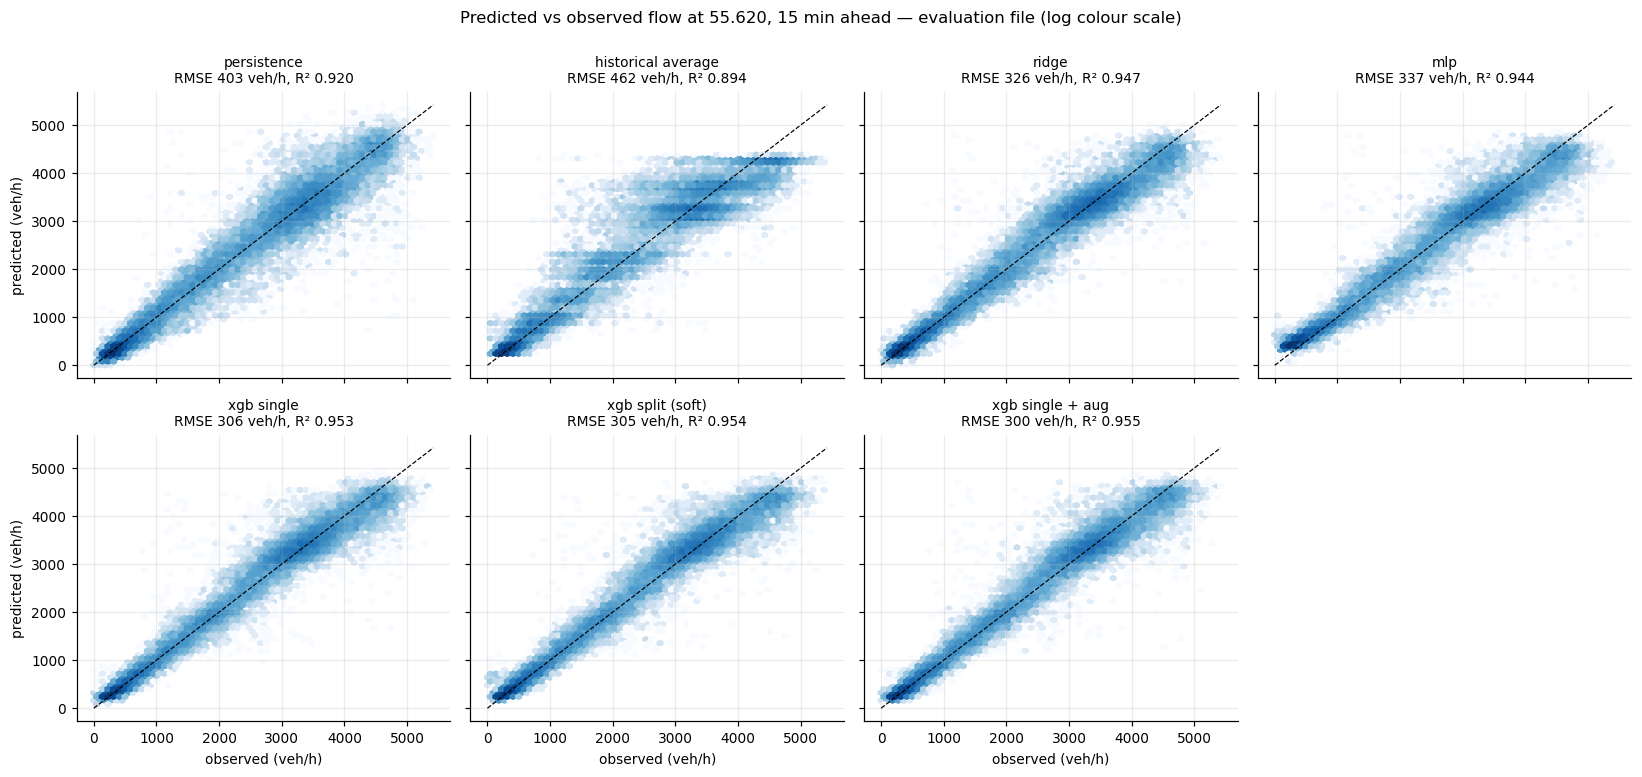

In [4]:
fig, axs = plt.subplots(2, 4, figsize=(15, 7), sharex=True, sharey=True)
lim = [0, np.nanpercentile(y, 99.9) * 1.05]
for a, k in zip(axs.flat, MODELS):
    a.hexbin(y, P[k], gridsize=60, bins="log", cmap="Blues", mincnt=1, extent=lim + lim)
    a.plot(lim, lim, "k--", lw=.8)
    r = np.sqrt((E[k] ** 2).mean()); r2 = 1 - (E[k] ** 2).sum() / ((y - y.mean()) ** 2).sum()
    a.set_title(f"{k}\nRMSE {r:.0f} veh/h, R² {r2:.3f}", fontsize=9)
axs.flat[-1].axis("off")
for a in axs[1]: a.set_xlabel("observed (veh/h)")
for a in axs[:, 0]: a.set_ylabel("predicted (veh/h)")
fig.suptitle(f"Predicted vs observed flow at 55.620, 15 min ahead — {SPLIT} file (log colour scale)", y=1.0)
fig.tight_layout(); save(fig, "pred_vs_obs_all_models"); plt.show()

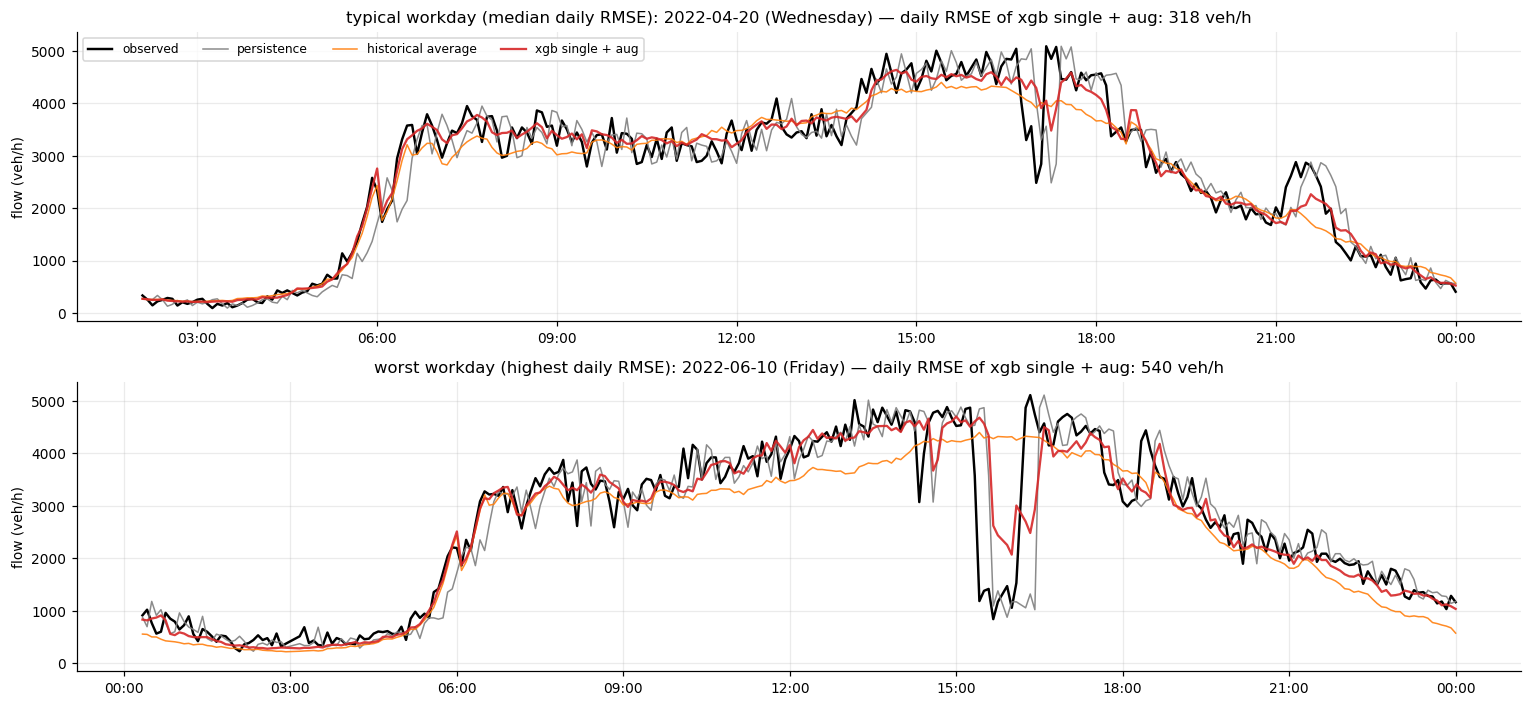

In [5]:
# a typical workday (median daily RMSE of the selected model) and the worst workday, full 24 h
dr = np.sqrt((E[SELECTED] ** 2).groupby(meta.day).mean())
wdays = dr[meta.groupby("day")["offday"].first().reindex(dr.index) == 0]
pick = {"typical workday (median daily RMSE)": (wdays - wdays.median()).abs().idxmin(), "worst workday (highest daily RMSE)": wdays.idxmax()}
fig, ax = plt.subplots(2, 1, figsize=(14, 6.5), sharey=True)
for a, (lab, d0) in zip(ax, pick.items()):
    w = meta.day == d0; tt = D.index[w] + pd.Timedelta(minutes=15)
    a.plot(tt, y[w], color="k", lw=1.6, label="observed")
    for k in ["persistence", "historical average", SELECTED]:
        a.plot(tt, P.loc[w, k], color=COL[k], lw=1.5 if k == SELECTED else 1, alpha=.9, label=k)
    a.set(ylabel="flow (veh/h)", title=f"{lab}: {d0.date()} ({d0:%A}) — daily RMSE of {SELECTED}: {dr[d0]:.0f} veh/h")
    a.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M"))
ax[0].legend(ncol=4, fontsize=8)
fig.tight_layout(); save(fig, "timeseries_typical_worst_day"); plt.show()

## 2. Accuracy with uncertainty: day-block bootstrap confidence intervals
Whole days are resampled with replacement (2 000 times) and the RMSE is recomputed, so the intervals respect the within-day
correlation of the errors.

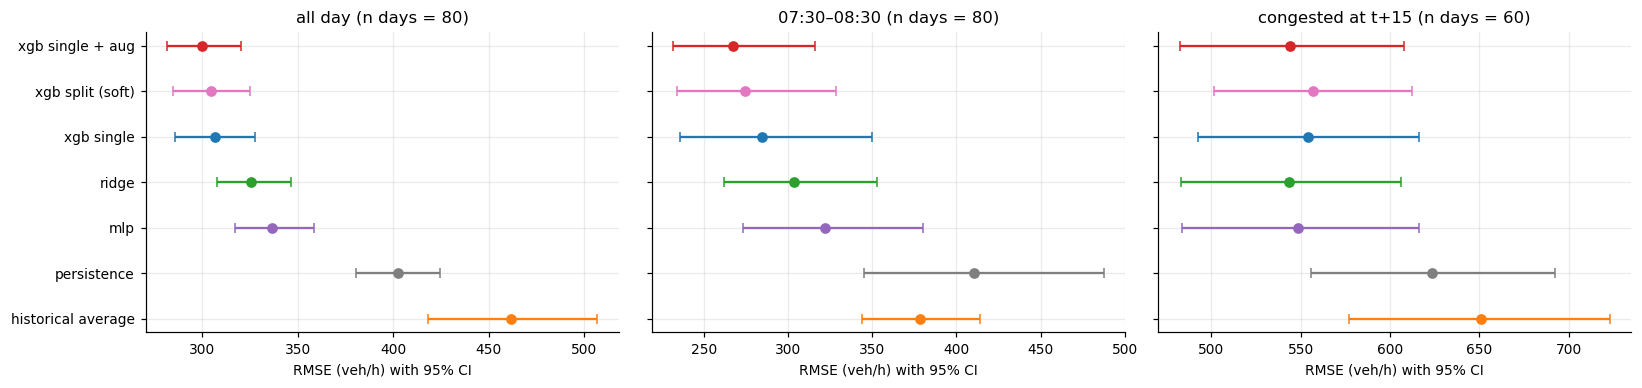

,all day,07:30–08:30,congested at t+15
xgb single + aug,"300 [282, 320]","268 [232, 316]","544 [482, 608]"
xgb split (soft),"305 [285, 325]","275 [234, 329]","557 [501, 612]"
xgb single,"306 [286, 328]","285 [236, 350]","554 [492, 616]"
ridge,"326 [308, 347]","304 [262, 353]","543 [483, 606]"
mlp,"337 [317, 358]","322 [273, 380]","548 [484, 616]"
persistence,"403 [381, 424]","411 [345, 487]","623 [556, 692]"
historical average,"462 [418, 507]","378 [344, 414]","651 [577, 723]"


In [6]:
def day_sums(ctx, mask, models):
    g = (ctx["E"].loc[mask, models] ** 2).groupby(ctx["meta"].day[mask])
    return g.sum(), g.size()

def boot_rmse(ctx, mask, models=MODELS, B=N_BOOT, seed=SEED):
    S, n = day_sums(ctx, mask, models)
    idx = np.random.default_rng(seed).integers(0, len(n), (B, len(n)))
    return pd.DataFrame(np.sqrt(S.to_numpy()[idx].sum(1) / n.to_numpy()[idx].sum(1)[:, None]), columns=S.columns)

panels = ["all day", "07:30–08:30", "congested at t+15"]
order = rmse_tab.loc["all day", MODELS].sort_values(ascending=False).index
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
ci_rows = {}
for a, s in zip(ax, panels):
    bt = boot_rmse(C, SUB[s]); lo, hi = bt.quantile(.025), bt.quantile(.975)
    for i, k in enumerate(order):
        r = rmse_tab.loc[s, k]
        a.errorbar(r, i, xerr=[[r - lo[k]], [hi[k] - r]], fmt="o", color=COL[k], capsize=3, ms=6)
        ci_rows[(s, k)] = {"RMSE": r, "95% CI low": lo[k], "95% CI high": hi[k]}
    a.set(title=f"{s} (n days = {C['meta'].day[SUB[s]].nunique()})", xlabel="RMSE (veh/h) with 95% CI")
ax[0].set_yticks(range(len(order)), order)
fig.tight_layout(); save(fig, "rmse_bootstrap_ci"); plt.show()
ci_tab = pd.DataFrame(ci_rows).T.round(0); ci_tab.to_csv(RES / f"rmse_ci_{SPLIT}_{TARGET}.csv")
ci_tab.assign(txt=lambda t: t["RMSE"].map("{:.0f}".format) + "  [" + t["95% CI low"].map("{:.0f}".format) + ", "
              + t["95% CI high"].map("{:.0f}".format) + "]")["txt"].unstack(0)[panels].loc[order[::-1]]

## 3. Planned model comparisons (H1–H4)
For each pair (A, B) the **loss differential** is d = e_A² − e_B². Tests:

* **paired t-test on daily mean d** (primary; H0: E[d] = 0) and **Wilcoxon signed-rank** on the same daily values (no normality assumption);
* **Diebold–Mariano** on all 5-min rows with a Newey–West (HAC) variance and the Harvey–Leybourne–Newbold small-sample correction for an h = 3-step forecast;
* the effect size is the RMSE difference with a paired day-block bootstrap 95 % CI.

p-values of the primary test are Holm-adjusted over the family of planned comparisons.

In [7]:
def holm(p):
    p = np.asarray(p, float); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for r, i in enumerate(o):
        run = max(run, (m - r) * p[i]); adj[i] = min(1.0, run)
    return adj

def nw_lag(n): return int(np.floor(4 * (n / 100) ** (2 / 9)))

def dm_test(ea, eb, alternative="two-sided", h=H):
    d = (ea ** 2 - eb ** 2).to_numpy(); n = len(d); L = nw_lag(n); dc = d - d.mean()
    lrv = dc @ dc / n + 2 * sum((1 - k / (L + 1)) * (dc[k:] @ dc[:-k]) / n for k in range(1, L + 1))
    stat = d.mean() / np.sqrt(lrv / n) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    p = {"two-sided": 2 * stats.t.sf(abs(stat), n - 1), "less": stats.t.cdf(stat, n - 1), "greater": stats.t.sf(stat, n - 1)}[alternative]
    return stat, p

def paired_boot_drmse(ctx, a, b, mask, B=N_BOOT, seed=SEED):
    S, n = day_sums(ctx, mask, [a, b]); S, n = S.to_numpy(), n.to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(n), (B, len(n)))
    r = np.sqrt(S[idx].sum(1) / n[idx].sum(1)[:, None])
    return np.percentile(r[:, 0] - r[:, 1], [2.5, 97.5])

def compare(ctx, a, b, sub, alternative="two-sided"):
    m = ctx["SUB"][sub]; E_, day = ctx["E"], ctx["meta"].day
    L = (E_.loc[m, [a, b]] ** 2).groupby(day[m]).mean(); d = L[a] - L[b]
    t = stats.ttest_1samp(d, 0, alternative=alternative); w = stats.wilcoxon(d, alternative=alternative)
    dm, pdm = dm_test(E_.loc[m, a], E_.loc[m, b], alternative)
    ra, rb = np.sqrt((E_.loc[m, a] ** 2).mean()), np.sqrt((E_.loc[m, b] ** 2).mean())
    lo, hi = paired_boot_drmse(ctx, a, b, m)
    return {"file": ctx["split"], "subset": sub, "A": a, "B": b,
            "H1 (alternative)": "A more accurate than B" if alternative == "less" else "A ≠ B",
            "days": len(d), "RMSE A": round(ra, 1), "RMSE B": round(rb, 1), "ΔRMSE A−B": round(ra - rb, 1),
            "ΔRMSE 95% CI": f"[{lo:.1f}, {hi:.1f}]", "t (days)": round(t.statistic, 2), "p t-test": t.pvalue,
            "p Wilcoxon": w.pvalue, "DM stat": round(dm, 2), "p DM": pdm}

PLAN = [("H1", SELECTED, "persistence", "all day", "less"),
        ("H1", SELECTED, "persistence", "07:30–08:30", "less"),
        ("H1", SELECTED, "historical average", "all day", "less"),
        ("H2", "xgb split (soft)", "xgb single", "all day", "two-sided"),
        ("H2", "xgb split (soft)", "xgb single", "congested at t+15", "two-sided"),
        ("H3", SELECTED, "xgb single", "all day", "two-sided"),
        ("H4", SELECTED, "ridge", "all day", "two-sided"),
        ("H4", SELECTED, "mlp", "all day", "two-sided")]

ctxs = [C] + ([make_ctx("final_evaluation")] if CONFIRM_ON_FINAL else [])
tables = []
for ctx in ctxs:
    t = pd.DataFrame([{"H": h, **compare(ctx, a, b, s, alt)} for h, a, b, s, alt in PLAN])
    t["p t-test (Holm)"] = holm(t["p t-test"])
    t["decision (α=0.05)"] = np.where(t["p t-test (Holm)"] < ALPHA, "reject H0", "do not reject H0")
    tables.append(t)
PLANNED = pd.concat(tables, ignore_index=True)
PLANNED.to_csv(RES / f"hypothesis_tests_planned_{TARGET}.csv", index=False)
show(PLANNED, ["p t-test", "p Wilcoxon", "p DM", "p t-test (Holm)"])

,H,file,subset,A,B,H1 (alternative),days,RMSE A,RMSE B,ΔRMSE A−B,ΔRMSE 95% CI,t (days),p t-test,p Wilcoxon,DM stat,p DM,p t-test (Holm),decision (α=0.05)
0,H1,evaluation,all day,xgb single + aug,persistence,A more accurate than B,80,300.0,402.6,-102.6,"[-112.7, -92.5]",-15.63,3.4e-26,4.2e-15,-20.18,4.6e-90,2.7e-25,reject H0
1,H1,evaluation,07:30–08:30,xgb single + aug,persistence,A more accurate than B,80,267.6,410.7,-143.1,"[-195.3, -103.7]",-4.33,2.2e-05,3e-13,-4.99,3.6e-07,8.7e-05,reject H0
2,H1,evaluation,all day,xgb single + aug,historical average,A more accurate than B,80,300.0,462.0,-162.0,"[-205.4, -122.5]",-6.25,9.6e-09,3.9e-15,-14.44,2.4e-47,4.8e-08,reject H0
3,H2,evaluation,all day,xgb split (soft),xgb single,A ≠ B,80,304.6,306.4,-1.7,"[-4.4, 1.1]",-1.17,0.25,0.35,-1.18,0.24,0.49,do not reject H0
4,H2,evaluation,congested at t+15,xgb split (soft),xgb single,A ≠ B,60,556.9,554.3,2.6,"[-9.8, 15.6]",0.57,0.57,0.11,0.46,0.64,0.57,do not reject H0
5,H3,evaluation,all day,xgb single + aug,xgb single,A ≠ B,80,300.0,306.4,-6.4,"[-12.3, -1.5]",-2.21,0.03,0.12,-3.90,9.8e-05,0.091,do not reject H0
6,H4,evaluation,all day,xgb single + aug,ridge,A ≠ B,80,300.0,325.7,-25.7,"[-30.1, -21.2]",-10.87,2.4e-17,4.4e-13,-11.54,1e-30,1.7e-16,reject H0
7,H4,evaluation,all day,xgb single + aug,mlp,A ≠ B,80,300.0,336.6,-36.6,"[-44.2, -29.6]",-8.93,1.3e-13,1.9e-13,-11.84,2.9e-32,7.9e-13,reject H0
8,H1,final_evaluation,all day,xgb single + aug,persistence,A more accurate than B,99,291.2,390.3,-99.1,"[-107.0, -90.8]",-17.84,7.7e-33,3.5e-18,-21.74,3.1e-104,6.2e-32,reject H0
9,H1,final_evaluation,07:30–08:30,xgb single + aug,persistence,A more accurate than B,97,301.2,400.2,-99.1,"[-119.0, -80.3]",-8.20,5.3e-13,7.8e-16,-9.37,1.6e-20,2.7e-12,reject H0


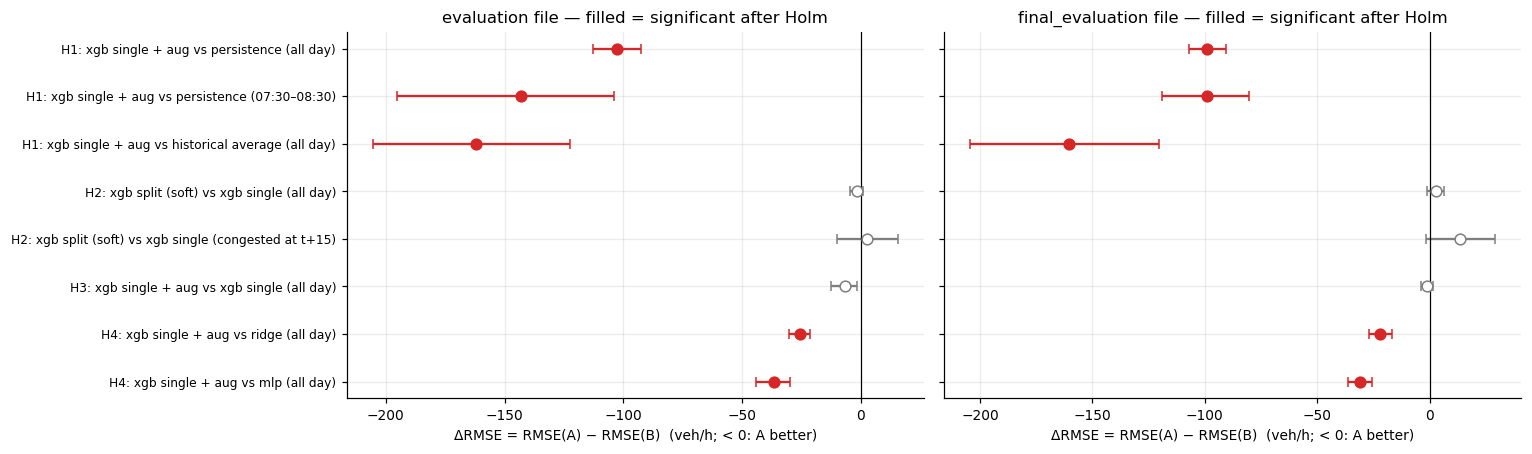

In [8]:
# forest plot of the effect sizes (ΔRMSE with paired day-bootstrap 95% CI)
fig, axs = plt.subplots(1, len(tables), figsize=(7 * len(tables), 4.2), sharey=True, squeeze=False)
for a, t in zip(axs[0], tables):
    for i, r in t.iloc[::-1].reset_index(drop=True).iterrows():
        lo, hi = [float(v) for v in r["ΔRMSE 95% CI"].strip("[]").split(",")]
        sig = r["p t-test (Holm)"] < ALPHA
        a.errorbar(r["ΔRMSE A−B"], i, xerr=[[r["ΔRMSE A−B"] - lo], [hi - r["ΔRMSE A−B"]]], fmt="o",
                   color="C3" if sig else "C7", mfc="C3" if sig else "white", capsize=3, ms=7)
    a.axvline(0, color="k", lw=.8)
    a.set_yticks(range(len(t)), [f"{r.H}: {r.A} vs {r.B} ({r.subset})" for r in t.iloc[::-1].itertuples()], fontsize=8)
    a.set(title=f"{t['file'].iat[0]} file — filled = significant after Holm", xlabel="ΔRMSE = RMSE(A) − RMSE(B)  (veh/h; < 0: A better)")
fig.tight_layout(); save(fig, "planned_comparisons_forest"); plt.show()

## 4. All pairwise comparisons and the Friedman test (H5)
**Pairwise:** every pair of models on the all-day subset, paired day-level t-test, Holm-adjusted over all 21 pairs.
**Friedman test:** models are ranked within each day by daily RMSE (1 = best); H0 = all models have the same expected rank.
If rejected, the **Nemenyi** critical difference (CD) says which mean ranks differ: two models differ significantly if their mean ranks
are more than CD apart (in the plot: their intervals of half-width CD/2 do not overlap).

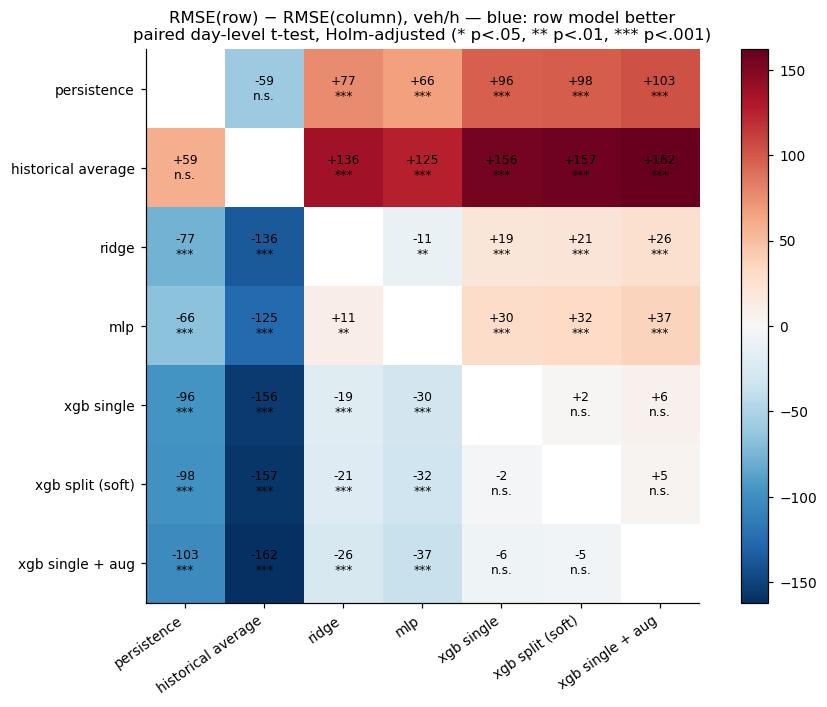

In [9]:
mall = SUB["all day"]
Ld = (E.loc[mall, MODELS] ** 2).groupby(meta.day[mall]).mean()
rm = np.sqrt((E.loc[mall, MODELS] ** 2).mean())
pairs = [(a, b) for i, a in enumerate(MODELS) for b in MODELS[i + 1:]]
pv = [stats.ttest_1samp(Ld[a] - Ld[b], 0).pvalue for a, b in pairs]
padj = dict(zip(pairs, holm(pv)))
Mdiff = pd.DataFrame(np.nan, index=MODELS, columns=MODELS); Mp = Mdiff.copy()
for (a, b), p in padj.items():
    Mdiff.loc[a, b], Mdiff.loc[b, a] = rm[a] - rm[b], rm[b] - rm[a]; Mp.loc[a, b] = Mp.loc[b, a] = p
fig, ax = plt.subplots(figsize=(8.5, 6.5))
v = np.nanmax(np.abs(Mdiff.to_numpy()))
im = ax.imshow(Mdiff, cmap="RdBu_r", vmin=-v, vmax=v)
for i in range(len(MODELS)):
    for j in range(len(MODELS)):
        if i != j:
            p = Mp.iloc[i, j]; st = "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else "n.s."
            ax.text(j, i, f"{Mdiff.iloc[i, j]:+.0f}\n{st}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(len(MODELS)), MODELS, rotation=35, ha="right"); ax.set_yticks(range(len(MODELS)), MODELS); ax.grid(False)
ax.set_title("RMSE(row) − RMSE(column), veh/h — blue: row model better\npaired day-level t-test, Holm-adjusted (* p<.05, ** p<.01, *** p<.001)")
fig.colorbar(im, ax=ax, fraction=.04); fig.tight_layout(); save(fig, "pairwise_matrix"); plt.show()

Friedman χ²(6) = 352.2, p = 5.3e-73  (N = 80 days) | Nemenyi CD = 1.01 ranks


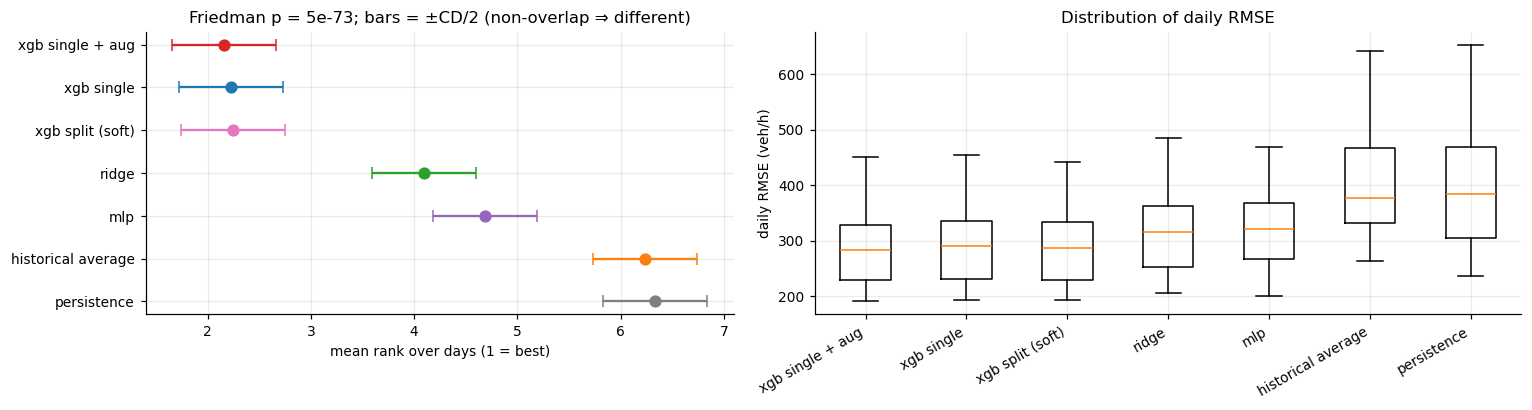

In [10]:
R = np.sqrt(Ld)                        # daily RMSE per model
ranks = R.rank(axis=1)                 # 1 = best on that day
fr = stats.friedmanchisquare(*[R[k] for k in MODELS])
k, N = len(MODELS), len(R)
q_a = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850, 7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164}[k]
CD = q_a * np.sqrt(k * (k + 1) / (6 * N))
mr = ranks.mean().sort_values()
print(f"Friedman χ²({k - 1}) = {fr.statistic:.1f}, p = {fr.pvalue:.2g}  (N = {N} days) | Nemenyi CD = {CD:.2f} ranks")
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1, 1.2]})
for i, (m_, r_) in enumerate(mr.items()):
    ax[0].errorbar(r_, i, xerr=CD / 2, fmt="o", color=COL[m_], capsize=4, ms=7)
ax[0].set_yticks(range(k), mr.index); ax[0].invert_yaxis()
ax[0].set(xlabel="mean rank over days (1 = best)", title=f"Friedman p = {fr.pvalue:.1g}; bars = ±CD/2 (non-overlap ⇒ different)")
ax[1].boxplot([R[m_] for m_ in mr.index], showfliers=False)
ax[1].set_xticks(range(1, k + 1), mr.index, rotation=30, ha="right"); ax[1].set(ylabel="daily RMSE (veh/h)", title="Distribution of daily RMSE")
fig.tight_layout(); save(fig, "friedman_nemenyi"); plt.show()

## 5. Forecast unbiasedness and efficiency (H6): Mincer–Zarnowitz regression
Regress observed on predicted: **y = a + b·ŷ + ε**. A perfect (unbiased, efficient) forecast has **a = 0 and b = 1**; tested jointly with a
Wald F-test using HAC standard errors. b < 1 means the predictions vary *too much* (should be shrunk); b > 1 means they are too
cautious (too smooth). With > 20 000 rows even tiny deviations become "significant" — judge the **size** of a and b, not only the p-value.

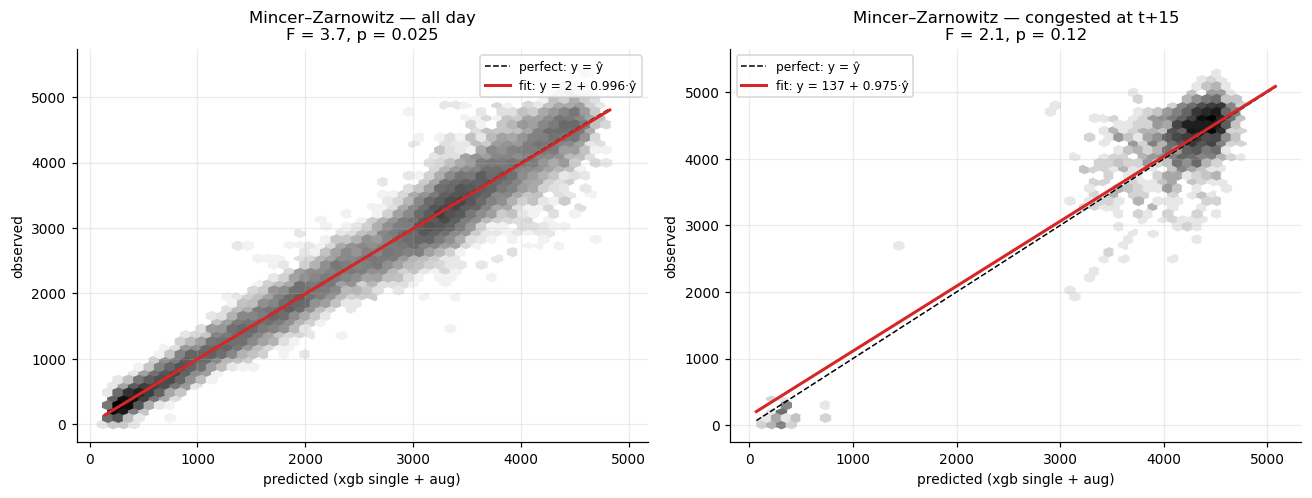

a     a 95% CI         b  \
all day           persistence       115.019072   [101, 129]  0.953514   
                  ridge              23.016361     [13, 33]  0.996413   
                  mlp               -78.528857   [-94, -63]  1.033439   
                  xgb single          3.431161     [-6, 13]  0.995482   
                  xgb single + aug    2.008549     [-7, 11]  0.995518   
07:30–08:30       persistence       264.330688   [196, 333]  0.902953   
                  ridge              21.266808    [-40, 82]  0.985299   
                  mlp                19.356604   [-64, 103]  1.002452   
                  xgb single         45.754891     [-3, 94]   0.97063   
                  xgb single + aug   25.324459    [-27, 77]  0.980074   
congested at t+15 persistence       724.690843  [381, 1069]  0.815843   
                  ridge             289.991696    [96, 484]  0.936479   
                  mlp               -65.011514  [-339, 209]  1.015245   
                  xgb single        201.066686   [-43, 445]  0.969906   
                  xgb single + aug  137.329212   [-83, 358]  0.974982   

                                          b 95% CI        R² F (a=0,b=1)  \
all day           persistence       [0.949, 0.958]  0.921818  171.314087   
                  ridge             [0.992, 1.001]  0.947511   12.904219   
                  mlp               [1.027, 1.040]  0.944792   57.874225   
                  xgb single        [0.991, 1.000]   0.95349    2.629949   
                  xgb single + aug  [0.991, 1.000]  0.955417    3.680111   
07:30–08:30       persistence       [0.881, 0.925]  0.889301   40.246483   
                  ridge             [0.965, 1.005]  0.934112    2.314565   
                  mlp               [0.976, 1.029]  0.925908    1.895328   
                  xgb single        [0.954, 0.988]  0.943276    9.308215   
                  xgb single + aug  [0.962, 0.998]   0.94946    5.776966   
congested at t+15 persistence       [0.737, 0.895]   0.65782   30.036772   
                  ridge             [0.892, 0.981]   0.71852    4.539589   
                  mlp               [0.951, 1.079]  0.708863    0.108868   
                  xgb single        [0.913, 1.026]  0.709684    9.496596   
                  xgb single + aug  [0.924, 1.026]  0.715056    2.092341   

                                          p  
all day           persistence       1.5e-74  
                  ridge             2.5e-06  
                  mlp               8.6e-26  
                  xgb single          0.072  
                  xgb single + aug    0.025  
07:30–08:30       persistence       1.5e-17  
                  ridge               0.099  
                  mlp                  0.15  
                  xgb single        9.8e-05  
                  xgb single + aug   0.0032  
congested at t+15 persistence       1.4e-13  
                  ridge               0.011  
                  mlp                   0.9  
                  xgb single        7.8e-05  
                  xgb single + aug     0.12

In [11]:
L_hac = nw_lag(len(y))
mz_rows = {}
for s in ["all day", "07:30–08:30", "congested at t+15"]:
    m = SUB[s]
    for k_ in ["persistence", "ridge", "mlp", "xgb single", SELECTED]:
        X = sm.add_constant(P.loc[m, k_].rename("pred"))
        res = sm.OLS(y[m], X).fit(cov_type="HAC", cov_kwds={"maxlags": L_hac})
        ft = res.f_test("const = 0, pred = 1"); ci = res.conf_int()
        mz_rows[(s, k_)] = {"a": res.params["const"], "a 95% CI": f"[{ci.loc['const', 0]:.0f}, {ci.loc['const', 1]:.0f}]",
                            "b": res.params["pred"], "b 95% CI": f"[{ci.loc['pred', 0]:.3f}, {ci.loc['pred', 1]:.3f}]",
                            "R²": res.rsquared, "F (a=0,b=1)": float(np.squeeze(ft.fvalue)), "p": float(np.squeeze(ft.pvalue))}
MZ = pd.DataFrame(mz_rows).T; MZ.to_csv(RES / f"mincer_zarnowitz_{SPLIT}_{TARGET}.csv")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for a, s in zip(ax, ["all day", "congested at t+15"]):
    m = SUB[s]; x_, y_ = P.loc[m, SELECTED], y[m]
    a.hexbin(x_, y_, gridsize=50, bins="log", cmap="Greys", mincnt=1)
    lo_, hi_ = np.percentile(np.r_[x_, y_], [0.5, 99.5]); xx = np.linspace(lo_, hi_, 2)
    r_ = MZ.loc[(s, SELECTED)]
    a.plot(xx, xx, "k--", lw=1, label="perfect: y = ŷ")
    a.plot(xx, r_["a"] + r_["b"] * xx, color="C3", lw=2, label=f"fit: y = {r_['a']:.0f} + {r_['b']:.3f}·ŷ")
    a.set(xlabel=f"predicted ({SELECTED})", ylabel="observed", title=f"Mincer–Zarnowitz — {s}\nF = {r_['F (a=0,b=1)']:.1f}, p = {r_['p']:.2g}")
    a.legend(fontsize=8)
fig.tight_layout(); save(fig, "mincer_zarnowitz"); plt.show()
show(MZ, ["p"], 3)

## 6. Residual diagnostics of the selected model (H6–H8)
* **Bias:** t-test on the daily mean error (H0: mean error = 0).
* **Normality:** Jarque–Bera, skewness, kurtosis, Q–Q plot. RMSE does not need normal errors, but prediction intervals built on a normal
  assumption would be wrong if the tails are heavy.
* **Autocorrelation:** errors of an optimal 3-step-ahead forecast are allowed to be correlated up to lag 2 (overlapping horizons), so
  the Ljung–Box statistic is computed on **lags 3–24** only (H0: no autocorrelation left there). Remaining autocorrelation = predictable
  structure the model did not use.
* **Heteroscedasticity by regime:** is the error larger in congestion? Mann–Whitney on |e| (row level, optimistic p because rows are not
  independent), Brown–Forsythe test for equal variance, and a **day-level** Wilcoxon test on mean |e| in congested vs free periods of the same day.

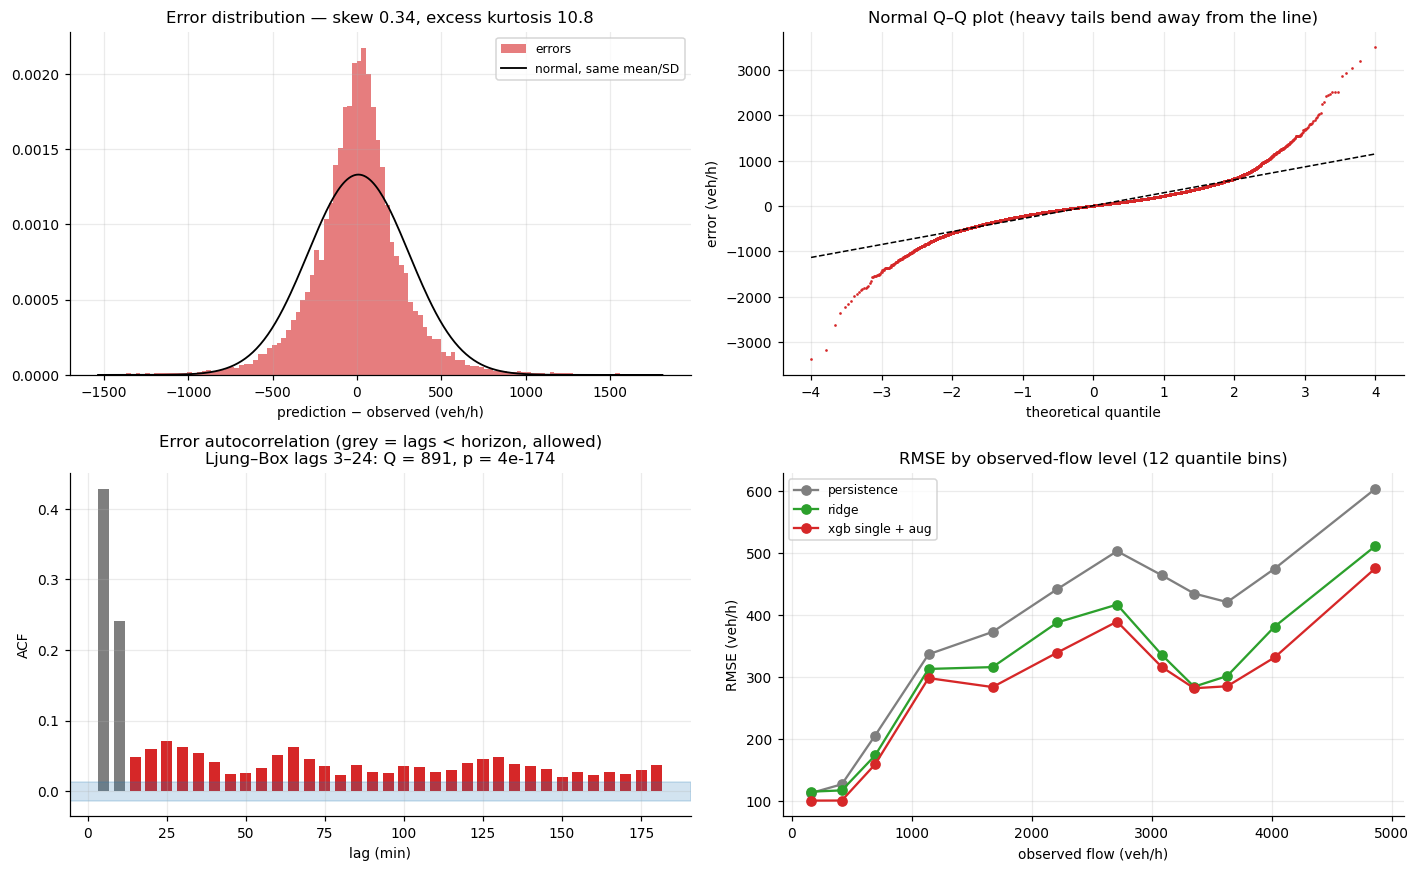

,H,question,test,statistic,p,effect
0,H6,mean error = 0 (unbiased)?,t-test on daily mean error,1.27,0.21,mean error +8.4 veh/h
1,H7,errors normal?,Jarque–Bera,105715.24,0,"skew 0.34, excess kurtosis 10.76"
2,H7,no autocorrelation at lags ≥ 3?,Ljung–Box lags 3–24,890.55,3.6e-174,"ACF lag 3 = 0.05, lag 6 = 0.06, lag 12 = 0.05"
3,H8,|error| larger in congestion?,"Mann–Whitney (rows, one-sided)",29296414.00,2.5e-177,median |e| 268 vs 129 veh/h
4,H8,|error| larger in congestion?,"Wilcoxon, 60 days with both regimes",1787.00,6.8e-11,mean daily |e| 366 vs 186 veh/h
5,H8,equal error variance across regimes?,Brown–Forsythe,1520.06,1.7e-321,SD 543 vs 259 veh/h


In [12]:
e = E[SELECTED]; SUMMARY = []
# bias
dme = e.groupby(meta.day).mean(); tb = stats.ttest_1samp(dme, 0)
# normality
jb = stats.jarque_bera(e); sk, ku = stats.skew(e), stats.kurtosis(e)
# autocorrelation on a regular 5-min time grid (gaps = NaN)
grid = pd.date_range(e.index.min(), e.index.max(), freq=f"{RES_MIN}min")
eg = (e - e.mean()).reindex(grid)
acf = pd.Series({k_: pd.concat([eg, eg.shift(k_)], axis=1).dropna().corr().iloc[0, 1] for k_ in range(1, 37)})
n = e.size; K = 24
Q = n * (n + 2) * sum(acf[k_] ** 2 / (n - k_) for k_ in range(H, K + 1)); dfq = K - H + 1; p_lb = stats.chi2.sf(Q, dfq)
# regimes
ae = e.abs(); fr_, co_ = meta.reg_y == 0, meta.reg_y == 1
mw = stats.mannwhitneyu(ae[co_], ae[fr_], alternative="greater")
bf = stats.levene(e[fr_], e[co_], center="median")
both = pd.DataFrame({"free": ae[fr_].groupby(meta.day[fr_]).mean(), "cong": ae[co_].groupby(meta.day[co_]).mean()}).dropna()
wd = stats.wilcoxon(both["cong"], both["free"], alternative="greater")

SUMMARY += [
    {"H": "H6", "question": "mean error = 0 (unbiased)?", "test": "t-test on daily mean error", "statistic": tb.statistic,
     "p": tb.pvalue, "effect": f"mean error {e.mean():+.1f} veh/h"},
    {"H": "H7", "question": "errors normal?", "test": "Jarque–Bera", "statistic": jb.statistic, "p": jb.pvalue,
     "effect": f"skew {sk:.2f}, excess kurtosis {ku:.2f}"},
    {"H": "H7", "question": "no autocorrelation at lags ≥ 3?", "test": f"Ljung–Box lags {H}–{K}", "statistic": Q, "p": p_lb,
     "effect": f"ACF lag 3 = {acf[3]:.2f}, lag 6 = {acf[6]:.2f}, lag 12 = {acf[12]:.2f}"},
    {"H": "H8", "question": "|error| larger in congestion?", "test": "Mann–Whitney (rows, one-sided)", "statistic": mw.statistic,
     "p": mw.pvalue, "effect": f"median |e| {ae[co_].median():.0f} vs {ae[fr_].median():.0f} veh/h"},
    {"H": "H8", "question": "|error| larger in congestion?", "test": f"Wilcoxon, {len(both)} days with both regimes", "statistic": wd.statistic,
     "p": wd.pvalue, "effect": f"mean daily |e| {both.cong.mean():.0f} vs {both.free.mean():.0f} veh/h"},
    {"H": "H8", "question": "equal error variance across regimes?", "test": "Brown–Forsythe", "statistic": bf.statistic,
     "p": bf.pvalue, "effect": f"SD {e[co_].std():.0f} vs {e[fr_].std():.0f} veh/h"}]

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
xx = np.linspace(np.percentile(e, .1), np.percentile(e, 99.9), 300)
ax[0, 0].hist(e, bins=120, range=(xx[0], xx[-1]), density=True, color="C3", alpha=.6, label="errors")
ax[0, 0].plot(xx, stats.norm.pdf(xx, e.mean(), e.std()), "k", lw=1.2, label="normal, same mean/SD")
ax[0, 0].set(title=f"Error distribution — skew {sk:.2f}, excess kurtosis {ku:.1f}", xlabel="prediction − observed (veh/h)"); ax[0, 0].legend(fontsize=8)
(osm, osr), (sl, ic, _) = stats.probplot(e, dist="norm")
ax[0, 1].plot(osm, osr, ".", ms=1.5, color="C3"); ax[0, 1].plot(osm, sl * osm + ic, "k--", lw=1)
ax[0, 1].set(title="Normal Q–Q plot (heavy tails bend away from the line)", xlabel="theoretical quantile", ylabel="error (veh/h)")
ax[1, 0].bar(acf.index * RES_MIN, acf.values, width=3.5, color=["C7" if k_ < H else "C3" for k_ in acf.index])
ax[1, 0].axhspan(-1.96 / np.sqrt(n), 1.96 / np.sqrt(n), color="C0", alpha=.2)
ax[1, 0].set(title=f"Error autocorrelation (grey = lags < horizon, allowed)\nLjung–Box lags {H}–{K}: Q = {Q:.0f}, p = {p_lb:.1g}",
             xlabel="lag (min)", ylabel="ACF")
fb = pd.qcut(y, 12)
g = pd.DataFrame({k_: E[k_] for k_ in ["persistence", "ridge", SELECTED]}).groupby(fb, observed=True)
for k_ in ["persistence", "ridge", SELECTED]:
    ax[1, 1].plot([iv.mid for iv in g[k_].mean().index], np.sqrt((g[k_].apply(lambda s: (s ** 2).mean()))), "o-", color=COL[k_], label=k_)
ax[1, 1].set(title="RMSE by observed-flow level (12 quantile bins)", xlabel="observed flow (veh/h)", ylabel="RMSE (veh/h)"); ax[1, 1].legend(fontsize=8)
fig.tight_layout(); save(fig, "residual_diagnostics"); plt.show()
show(pd.DataFrame(SUMMARY), ["p"])

## 7. Where in the day do the models help? (skill score vs persistence)

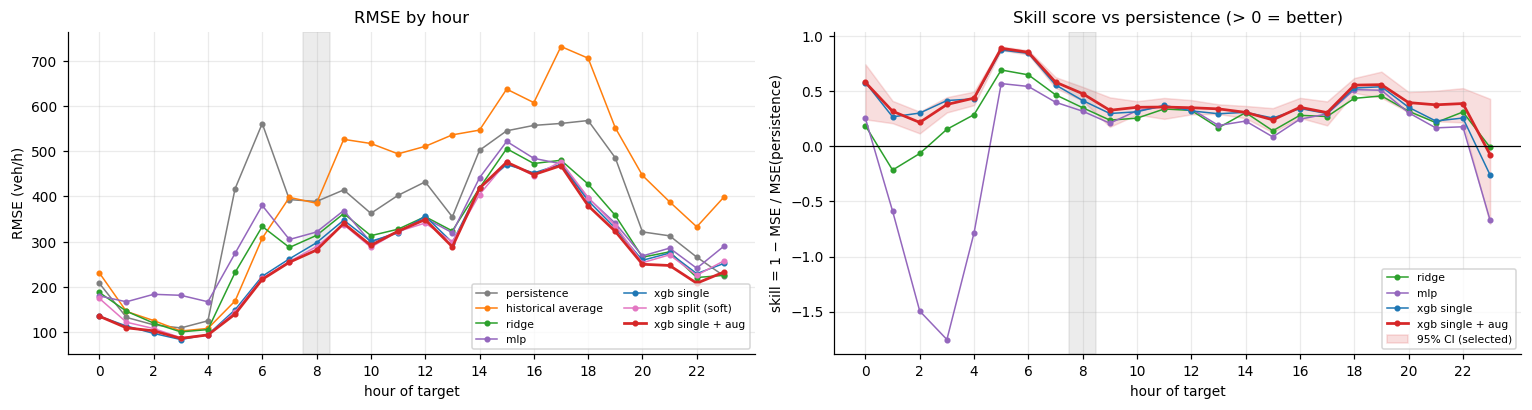

In [13]:
hour = meta.tod // 60
mse_h = (E ** 2).groupby(hour).mean()
ss = 1 - mse_h.div(mse_h["persistence"], axis=0)
# day-block bootstrap band for the selected model's skill
rng = np.random.default_rng(SEED); dlist = meta.day.unique(); band = []
Sd = ((E[[SELECTED, "persistence"]] ** 2).assign(hour=hour, day=meta.day).groupby(["day", "hour"]).sum())
for _ in range(500):
    pick = pd.Index(rng.choice(dlist, len(dlist)))
    s_ = Sd.loc[pick].groupby(level="hour").sum()
    band.append(1 - s_[SELECTED] / s_["persistence"])
band = pd.concat(band, axis=1)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
for k_ in MODELS:
    ax[0].plot(np.sqrt(mse_h[k_]), "o-", ms=3, color=COL[k_], label=k_, lw=1.8 if k_ == SELECTED else 1)
ax[0].axvspan(7.5, 8.5, color="grey", alpha=.15); ax[0].set(xlabel="hour of target", ylabel="RMSE (veh/h)", title="RMSE by hour"); ax[0].legend(fontsize=7, ncol=2)
for k_ in ["ridge", "mlp", "xgb single", SELECTED]:
    ax[1].plot(ss[k_], "o-", ms=3, color=COL[k_], label=k_, lw=1.8 if k_ == SELECTED else 1)
ax[1].fill_between(band.index, band.quantile(.025, axis=1), band.quantile(.975, axis=1), color=COL[SELECTED], alpha=.15, label="95% CI (selected)")
ax[1].axhline(0, color="k", lw=.8); ax[1].axvspan(7.5, 8.5, color="grey", alpha=.15)
ax[1].set(xlabel="hour of target", ylabel="skill = 1 − MSE / MSE(persistence)", title="Skill score vs persistence (> 0 = better)"); ax[1].legend(fontsize=7)
for a in ax: a.set_xticks(range(0, 24, 2))
fig.tight_layout(); save(fig, "skill_by_hour"); plt.show()

## 8. Is 2022 like 2021? Distribution shift and bias stability (H9)
* **Kolmogorov–Smirnov** on the *daily mean* target flow (one value per day → independent) in the morning benchmark window and in the
  afternoon peak, workdays only, training + validation (2021) vs the evaluation file (2022).
* **Kruskal–Wallis** on the daily mean error of the selected model across the months of 2022 (H0: the bias is the same every month).

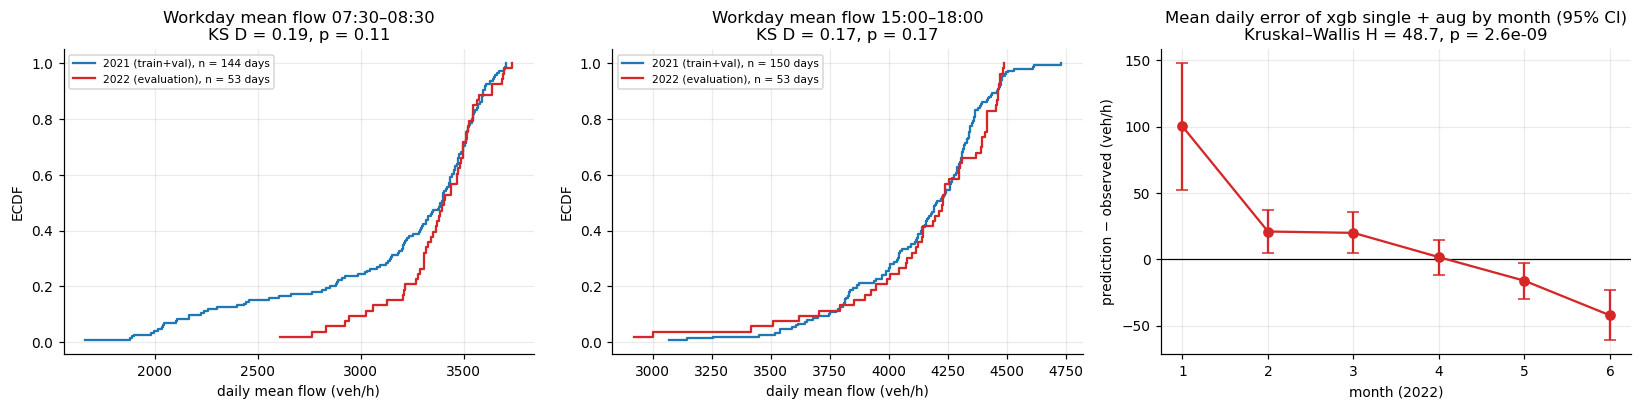

In [14]:
TR = pd.read_pickle(IN / "features_full.pkl")                     # all 2021
def daily_window_mean(F, lo, hi):
    m = F["tod_target_min"].between(lo, hi) & (F["is_offday"] == 0) & F[Y].notna()
    return F.loc[m, Y].groupby((F.index[m] - pd.Timedelta(minutes=RES_MIN)).normalize()).mean()
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, (lab, lo, hi) in zip(ax[:2], [("07:30–08:30", 450, 510), ("15:00–18:00", 900, 1080)]):
    a_, b_ = daily_window_mean(TR, lo, hi), daily_window_mean(D, lo, hi)
    ks = stats.ks_2samp(a_, b_)
    for s_, lab_, c_ in [(a_, "2021 (train+val)", "C0"), (b_, f"2022 ({SPLIT})", "C3")]:
        xs = np.sort(s_); a.step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post", color=c_, label=f"{lab_}, n = {len(xs)} days")
    a.set(title=f"Workday mean flow {lab}\nKS D = {ks.statistic:.2f}, p = {ks.pvalue:.2g}", xlabel="daily mean flow (veh/h)", ylabel="ECDF"); a.legend(fontsize=7)
    SUMMARY.append({"H": "H9", "question": f"same flow distribution 2021 vs 2022 ({lab})?", "test": "KS on workday daily means",
                    "statistic": ks.statistic, "p": ks.pvalue, "effect": f"median {a_.median():.0f} vs {b_.median():.0f} veh/h"})
mon = dme.groupby(dme.index.month)
tab = mon.agg(["mean", "std", "count"]); half = stats.t.ppf(.975, tab["count"] - 1) * tab["std"] / np.sqrt(tab["count"])
kw = stats.kruskal(*[g_.values for _, g_ in mon])
ax[2].errorbar(tab.index, tab["mean"], yerr=half, fmt="o-", color=COL[SELECTED], capsize=4)
ax[2].axhline(0, color="k", lw=.8)
ax[2].set(title=f"Mean daily error of {SELECTED} by month (95% CI)\nKruskal–Wallis H = {kw.statistic:.1f}, p = {kw.pvalue:.2g}",
          xlabel="month (2022)", ylabel="prediction − observed (veh/h)")
SUMMARY.append({"H": "H9", "question": "bias the same in every month?", "test": "Kruskal–Wallis on daily mean error",
                "statistic": kw.statistic, "p": kw.pvalue, "effect": f"monthly mean error {tab['mean'].min():+.0f} … {tab['mean'].max():+.0f} veh/h"})
fig.tight_layout(); save(fig, "distribution_shift"); plt.show()

## 9. Robustness to sensor failures: does augmentation help significantly? (H10)
Same failure scenarios as A2 (inputs blanked in the evaluation file). For each scenario: paired day-level t-test of the augmented vs
the non-augmented model (two-sided), Holm-adjusted over the 8 comparisons.

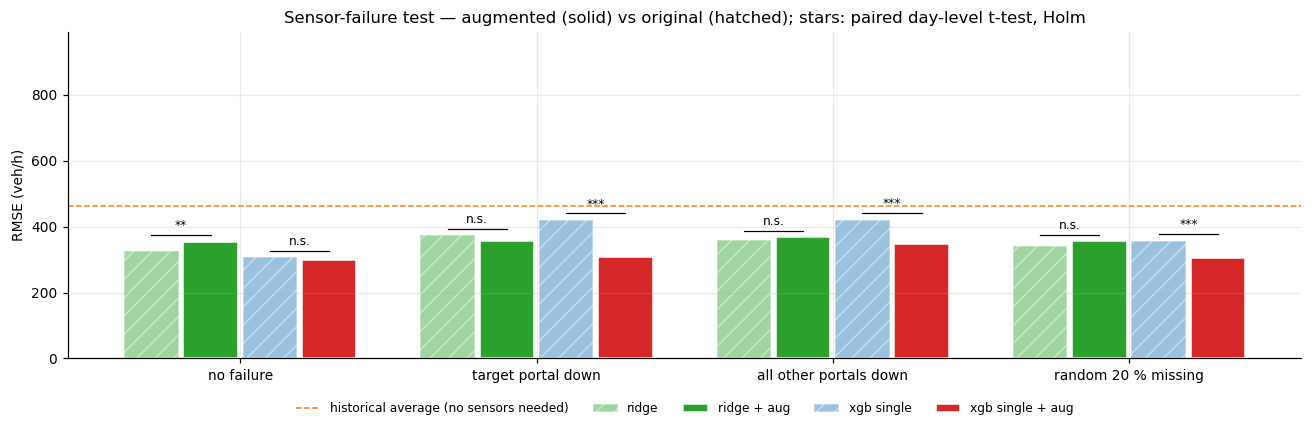

,scenario,A,B,RMSE A,RMSE B,t,p,p (Holm),decision
0,no failure,xgb single + aug,xgb single,300.0,306.4,-2.2,0.03,0.095,n.s.
1,no failure,ridge + aug,ridge,354.4,325.7,3.5,0.00081,0.004,significant
2,target portal down,xgb single + aug,xgb single,306.6,420.1,-8.5,1e-12,6.3e-12,significant
3,target portal down,ridge + aug,ridge,357.5,373.4,-2.3,0.024,0.095,n.s.
4,all other portals down,xgb single + aug,xgb single,346.7,421.5,-9.9,1.5e-15,1.2e-14,significant
5,all other portals down,ridge + aug,ridge,367.4,359.9,0.7,0.48,0.48,n.s.
6,random 20 % missing,xgb single + aug,xgb single,304.7,357.7,-9.2,3.5e-14,2.4e-13,significant
7,random 20 % missing,ridge + aug,ridge,355.0,342.0,1.5,0.15,0.3,n.s.


In [15]:
pf = tp.portal_feature_map(X_COLS)
own = pf[TARGET_P]; others = sorted({c for p_, cs in pf.items() if p_ != TARGET_P for c in cs} - set(own))
value_cols = sorted({c for cs in pf.values() for c in cs})
def mask_random(df, frac=0.2, seed=SEED):
    df = df.copy(); M_ = np.random.default_rng(seed).random((len(df), len(value_cols))) < frac
    df[value_cols] = df[value_cols].mask(M_); return df
SCEN = {"no failure": lambda df: df,
        "target portal down": lambda df: df.assign(**{c: np.nan for c in own}),
        "all other portals down": lambda df: df.assign(**{c: np.nan for c in others}),
        "random 20 % missing": mask_random}
def predict_rob(d):
    Zd = Z(d)
    return pd.DataFrame({"ridge": prep["ridge"].predict(Zd), "ridge + aug": prep["ridge_aug"].predict(Zd),
                         "xgb single": XM["xgb_single"].predict(d[X_COLS]), "xgb single + aug": XM["xgb_single_aug"].predict(d[X_COLS])}, index=d.index)
rows, rm_s = [], {}
for sc_name, fn in SCEN.items():
    Er = predict_rob(fn(D)).sub(y, axis=0); Ldr = (Er ** 2).groupby(meta.day).mean()
    rm_s[sc_name] = np.sqrt((Er ** 2).mean())
    for a_, b_ in [("xgb single + aug", "xgb single"), ("ridge + aug", "ridge")]:
        t_ = stats.ttest_1samp(Ldr[a_] - Ldr[b_], 0)
        rows.append({"scenario": sc_name, "A": a_, "B": b_, "RMSE A": rm_s[sc_name][a_], "RMSE B": rm_s[sc_name][b_], "t": t_.statistic, "p": t_.pvalue})
ROB = pd.DataFrame(rows); ROB["p (Holm)"] = holm(ROB["p"])
ROB["decision"] = np.where(ROB["p (Holm)"] < ALPHA, "significant", "n.s.")
RM = pd.DataFrame(rm_s).T
fig, ax = plt.subplots(figsize=(12, 4))
xs = np.arange(len(RM)); wdt = .2
for i, (k_, c_, hatch) in enumerate([("ridge", "C2", "//"), ("ridge + aug", "C2", ""), ("xgb single", "C0", "//"), ("xgb single + aug", "C3", "")]):
    ax.bar(xs + (i - 1.5) * wdt, RM[k_], wdt * .92, color=c_, alpha=.45 if hatch else 1, hatch=hatch, edgecolor="white", label=k_)
ymax = 900                                     # bars above this are clipped and labelled with their value
for j, sc_name in enumerate(RM.index):
    for i, k_ in enumerate(["ridge", "ridge + aug", "xgb single", "xgb single + aug"]):
        if RM.loc[sc_name, k_] > ymax:
            ax.text(j + (i - 1.5) * wdt, ymax * .9, f"{RM.loc[sc_name, k_]:.0f}\n(clipped)", ha="center", va="top", fontsize=7, rotation=90)
    for off, (a_, b_) in [(-wdt, ("ridge + aug", "ridge")), (wdt, ("xgb single + aug", "xgb single"))]:
        r_ = ROB[(ROB.scenario == sc_name) & (ROB.A == a_)].iloc[0]
        st = "***" if r_["p (Holm)"] < .001 else "**" if r_["p (Holm)"] < .01 else "*" if r_["p (Holm)"] < .05 else "n.s."
        top = min(RM.loc[sc_name, [a_, b_]].max(), ymax)
        ax.plot([j + off - wdt / 2, j + off + wdt / 2], [top + 20] * 2, color="k", lw=.8)
        ax.text(j + off, top + 28, st, ha="center", va="bottom", fontsize=8)
ax.axhline(rmse_tab.loc["all day", "historical average"], color="C1", ls="--", lw=1, label="historical average (no sensors needed)")
ax.set_xticks(xs, RM.index); ax.set(ylabel="RMSE (veh/h)", title="Sensor-failure test — augmented (solid) vs original (hatched); stars: paired day-level t-test, Holm")
ax.set_ylim(0, ymax + 90); ax.legend(fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(.5, -.1), frameon=False)
fig.tight_layout(); save(fig, "robustness_tests"); plt.show()
for r_ in ROB.itertuples():
    SUMMARY.append({"H": "H10", "question": f"{r_.A} = {r_.B} under '{r_.scenario}'?", "test": "paired day-level t-test (Holm)",
                    "statistic": r_.t, "p": r_[-2], "effect": f"RMSE {r_[4]:.0f} vs {r_[5]:.0f} veh/h"})
show(ROB, ["p", "p (Holm)"], 1)

## 10. Summary of all hypothesis tests

In [16]:
S1 = PLANNED.assign(question=lambda t: t["A"] + " vs " + t["B"] + " (" + t["subset"] + ", " + t["file"] + " file): " + t["H1 (alternative)"],
                    test="paired day-level t-test (Holm)", statistic=PLANNED["t (days)"], p=PLANNED["p t-test (Holm)"],
                    effect=lambda t: "ΔRMSE " + t["ΔRMSE A−B"].map("{:+.1f}".format) + " veh/h, 95% CI " + t["ΔRMSE 95% CI"])[
    ["H", "question", "test", "statistic", "p", "effect"]]
S2 = pd.DataFrame([{"H": "H5", "question": "all models equally accurate (daily RMSE ranks)?", "test": "Friedman",
                    "statistic": fr.statistic, "p": fr.pvalue, "effect": f"best mean rank: {mr.index[0]} ({mr.iloc[0]:.2f}); CD = {CD:.2f}"}]
                  + [{"H": "H6", "question": f"forecast unbiased & efficient (a=0, b=1)? — {k_}, {s}", "test": "Mincer–Zarnowitz Wald (HAC)",
                      "statistic": r_["F (a=0,b=1)"], "p": r_["p"], "effect": f"a = {r_['a']:.0f}, b = {r_['b']:.3f}"}
                     for (s, k_), r_ in MZ.iterrows() if k_ == SELECTED])
ALL = pd.concat([S1, S2, pd.DataFrame(SUMMARY)], ignore_index=True)
ALL["decision (α=0.05)"] = np.where(ALL["p"] < ALPHA, "reject H0", "do not reject H0")
ALL.to_csv(RES / f"hypothesis_tests_all_{TARGET}.csv", index=False)
pd.set_option("display.max_colwidth", 120); show(ALL, ["p"])

,H,question,test,statistic,p,effect,decision (α=0.05)
0,H1,"xgb single + aug vs persistence (all day, evaluation file): A more accurate than B",paired day-level t-test (Holm),-15.63,2.7e-25,"ΔRMSE -102.6 veh/h, 95% CI [-112.7, -92.5]",reject H0
1,H1,"xgb single + aug vs persistence (07:30–08:30, evaluation file): A more accurate than B",paired day-level t-test (Holm),-4.33,8.7e-05,"ΔRMSE -143.1 veh/h, 95% CI [-195.3, -103.7]",reject H0
2,H1,"xgb single + aug vs historical average (all day, evaluation file): A more accurate than B",paired day-level t-test (Holm),-6.25,4.8e-08,"ΔRMSE -162.0 veh/h, 95% CI [-205.4, -122.5]",reject H0
3,H2,"xgb split (soft) vs xgb single (all day, evaluation file): A ≠ B",paired day-level t-test (Holm),-1.17,0.49,"ΔRMSE -1.7 veh/h, 95% CI [-4.4, 1.1]",do not reject H0
4,H2,"xgb split (soft) vs xgb single (congested at t+15, evaluation file): A ≠ B",paired day-level t-test (Holm),0.57,0.57,"ΔRMSE +2.6 veh/h, 95% CI [-9.8, 15.6]",do not reject H0
5,H3,"xgb single + aug vs xgb single (all day, evaluation file): A ≠ B",paired day-level t-test (Holm),-2.21,0.091,"ΔRMSE -6.4 veh/h, 95% CI [-12.3, -1.5]",do not reject H0
6,H4,"xgb single + aug vs ridge (all day, evaluation file): A ≠ B",paired day-level t-test (Holm),-10.87,1.7e-16,"ΔRMSE -25.7 veh/h, 95% CI [-30.1, -21.2]",reject H0
7,H4,"xgb single + aug vs mlp (all day, evaluation file): A ≠ B",paired day-level t-test (Holm),-8.93,7.9e-13,"ΔRMSE -36.6 veh/h, 95% CI [-44.2, -29.6]",reject H0
8,H1,"xgb single + aug vs persistence (all day, final_evaluation file): A more accurate than B",paired day-level t-test (Holm),-17.84,6.2e-32,"ΔRMSE -99.1 veh/h, 95% CI [-107.0, -90.8]",reject H0
9,H1,"xgb single + aug vs persistence (07:30–08:30, final_evaluation file): A more accurate than B",paired day-level t-test (Holm),-8.20,2.7e-12,"ΔRMSE -99.1 veh/h, 95% CI [-119.0, -80.3]",reject H0


## Interpretation (leakage-safe rerun, evaluation file — check against your own numbers above)

**H1 — the model beats the baselines.** XGBoost + augmentation is 103 veh/h (≈ 25 %) better than persistence and ≈ 160 veh/h
better than the historical average all day; on the 07:30–08:30 benchmark 143 veh/h better than persistence. All Holm-adjusted
p < 10⁻⁴, with every test (t, Wilcoxon, DM) agreeing. **Confirmed on `final_evaluation`** (used once, corrected pipeline): 291 vs 390 veh/h all day (−99, CI −107…−91) and
301 vs 400 veh/h on 07:30–08:30 (−99, CI −119…−80), Holm p < 10⁻¹¹. H2–H4 give the same decisions on both files.

**H2 — regime-split models give no gain.** −1.7 veh/h all day (CI −4.4…1.1) and +2.6 in congestion (CI −9.8…15.6), both not
significant. The Friedman test (χ² = 352, p ≈ 10⁻⁷³) ranks the three XGBoost variants together (mean ranks 2.16–2.25, within
the Nemenyi CD of 1.01), clearly ahead of ridge (4.1), the MLP (4.7) and the baselines (6.2–6.3).

**H3 — augmentation is free.** Without sensor failures XGB + aug vs XGB: −6.4 veh/h (CI −12.3…−1.5), raw p = 0.03 but not
significant after Holm (p = 0.09) — if anything it helps a little. **H10:** under failures it helps significantly (target portal
down 420 → 307, other portals down 421 → 347, random 20 % missing 358 → 305 veh/h; all Holm p < 10⁻¹¹). For ridge, augmentation
costs 28 veh/h without failures (significant) and gains nothing under failures — a trade-off only for the linear model.

**H4 —** XGBoost is significantly better than ridge (−26 veh/h) and the MLP (−37 veh/h). The MLP is worse than persistence at
night (01:00–04:00: ≈ 170–185 vs 110–135 veh/h).

**H6 — calibration.** Mean error +8 veh/h, not different from 0 (p = 0.21). Mincer–Zarnowitz rejects a = 0, b = 1 all day
(p = 0.03) but the fitted line is y = 2 + 0.996·ŷ — detectable only because n ≈ 22 000; practically the forecasts are unbiased
and efficient. In congestion the test does not reject (p = 0.12).

**H7 — errors are not normal and not fully white.** Excess kurtosis ≈ 11 (heavy tails: rare large misses at congestion onsets, see
the worst day, where flow drops from 4 500 to 1 000 veh/h within 10 min). Beyond the 15-min horizon the autocorrelation is small
(0.05–0.06) but persistent over hours (Ljung–Box rejects): a slowly varying *daily* level the model does not fully capture → a
feature such as "today's deviation from the historical profile over the last hour" is a natural next improvement (tested in A4).
Prediction intervals should use empirical quantiles (by regime), not ±1.96·σ.

**H8 — congestion doubles the error:** median |e| 268 vs 129 veh/h; the day-level test (60 days with both regimes) confirms it
(p ≈ 10⁻¹⁰), so this is not an artefact of correlated rows.

**H9 — no flow shift, but a seasonal bias drift.** Workday daily-mean flows in 2022 are not significantly different from 2021 (KS
p = 0.11 and 0.17), but the monthly bias drifts from +100 veh/h in January to −42 veh/h in June (Kruskal–Wallis p ≈ 10⁻⁹): the model
was trained on June–December and over-predicts in winter. In operation it should be retrained regularly (e.g. monthly with a rolling window).

**Statistical vs practical significance.** With ~22 000 rows almost any difference becomes "significant" in row-level tests; the
day-level tests, the bootstrap CIs and the effect sizes in veh/h are what should be reported and discussed.